# Pair 3. 3D objects for a virtual open day (one photo -> 3D)

**Business need:** turn a single photo of an object into a 3D model for a virtual open-day tour, without a 3D artist.

| | System A | System B  |
|---|---|---|
| Model | **TripoSR** | **TRELLIS** |
| How it works | A transformer looks at the photo once and predicts a **triplane NeRF** (a 3D field read from three 2D feature planes); a mesh is extracted with marching cubes | Generates a *structured 3D latent* (sparse voxels) with **rectified-flow** transformers, then decodes it to a mesh or **3D Gaussians** |
| Lecture link | Week 4 (NeRF), Week 5 (feed-forward 3D instead of per-object optimisation) | Week 4 (3D Gaussian Splatting), Week 10 (flow matching) |
| Runs on | Laptop CPU | Free Hugging Face Space (needs a free login) |

**Inputs:** 6 product-style photos of single objects in `data/p3_images/`.

**Key question from Week 5:** one photo shows only one side, so the back must be *generated*. Testers rate how plausible the unseen sides look.

In [1]:
import os, time, shutil, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import trimesh

In [2]:
os.makedirs("outputs/p3/A", exist_ok=True)
os.makedirs("outputs/p3/B", exist_ok=True)
os.makedirs("results/p3", exist_ok=True)

objects = pd.read_csv("data/p3_objects.csv")
times_log = []
objects

,id,image,description
0,o01,mug.jpg,a handmade ceramic mug
1,o02,backpack.jpg,a light blue backpack
2,o03,plant.jpg,a snake plant in a speckled pot
3,o04,lamp.jpg,a black desk lamp
4,o05,shoe.jpg,a black leather sneaker
5,o06,bottle.jpg,a pink Macquarie University water bottle


## System A: TripoSR

TripoSR's own script is called once per photo, using TripoSR's environment. 
TripoSR is not on pip. It runs from its own GitHub folder with **its own small environment**.

In [3]:
TRIPOSR_PYTHON = ".venv-tripo/bin/python"      # TripoSR's own environment

for _, o in objects.iterrows():
    start = time.time()
    subprocess.run([TRIPOSR_PYTHON, "run.py", f"../data/p3_images/{o['image']}",
                    "--output-dir", f"../outputs/p3/A/{o['id']}",
                    "--model-save-format", "glb", "--device", "cpu"], cwd="TripoSR")
    os.rename(f"outputs/p3/A/{o['id']}/0/mesh.glb", f"outputs/p3/A/{o['id']}.glb")
    times_log.append({"system": "A", "item": o["id"], "seconds": time.time() - start, "hand_minutes": 0})

pd.DataFrame(times_log).to_csv("results/p3/times_A.csv", index=False)   # each system saves its own times

2026-10-22 14:02:51,308 - INFO - Initializing model ...
2026-10-22 14:02:55,639 - INFO - Initializing model finished in 4329.42ms.
2026-10-22 14:02:55,640 - INFO - Processing images ...
2026-10-22 14:03:06,796 - INFO - Processing images finished in 11156.35ms.
2026-10-22 14:03:06,796 - INFO - Running image 1/1 ...
2026-10-22 14:03:06,796 - INFO - Running model ...
2026-10-22 14:03:10,476 - INFO - Running model finished in 3680.14ms.
2026-10-22 14:03:10,476 - INFO - Extracting mesh ...
2026-10-22 14:03:16,949 - INFO - Extracting mesh finished in 6472.23ms.
2026-10-22 14:03:16,949 - INFO - Exporting mesh ...
2026-10-22 14:03:16,955 - INFO - Exporting mesh finished in 5.75ms.
2026-10-22 14:03:19,225 - INFO - Initializing model ...
2026-10-22 14:03:22,773 - INFO - Initializing model finished in 3547.84ms.
2026-10-22 14:03:22,773 - INFO - Processing images ...
2026-10-22 14:03:33,029 - INFO - Processing images finished in 10255.82ms.
2026-10-22 14:03:33,029 - INFO - Running image 1/1 ...
20

## System B: TRELLIS (free Hugging Face Space)

TRELLIS runs on its free demo page (`trellis-community/TRELLIS`). 

**One-time step:** the free GPU quota is per Hugging Face account,  make a free account and run `hf auth login` once in a terminal (paste a *read* token).

In [4]:
from gradio_client import Client, handle_file
from huggingface_hub import get_token

trellis = Client("trellis-community/TRELLIS", token=get_token())      # uses your `hf auth login`
trellis.predict(api_name="/start_session")

b_times = pd.read_csv("results/p3/times_B.csv") if os.path.exists("results/p3/times_B.csv") else pd.DataFrame()
for _, o in objects.iterrows():
    if os.path.exists(f"outputs/p3/B/{o['id']}.glb"):
        continue                                                      # already made on an earlier run
    start = time.time()
    # Step 1 on the demo page: remove the background (TripoSR does this inside its own script too)
    cutout = trellis.predict(image=handle_file(f"data/p3_images/{o['image']}"), api_name="/preprocess_image")
    # Step 2: generate the 3D model from the cut-out and export it as a GLB file
    result = trellis.predict(image=handle_file(cutout), multiimages=[], seed=0,
                             ss_guidance_strength=7.5, ss_sampling_steps=12, slat_guidance_strength=3.0,
                             slat_sampling_steps=12, multiimage_algo="stochastic", mesh_simplify=0.95,
                             texture_size=1024, api_name="/generate_and_extract_glb")
    glb_file = [r for r in result if isinstance(r, str) and r.endswith(".glb")][0]
    shutil.copy(glb_file, f"outputs/p3/B/{o['id']}.glb")
    b_times = pd.concat([b_times, pd.DataFrame([{"system": "B", "item": o["id"], "seconds": time.time() - start,
                                                 "hand_minutes": 0}])])
    b_times.to_csv("results/p3/times_B.csv", index=False)     

Loaded as API: https://trellis-community-trellis.hf.space


## Technical metrics

- **generated**: the mesh file exists.
- **single_piece**: the mesh is one connected object, not floating fragments (1 = yes). Vertices repeated along texture seams are merged first, otherwise a textured mesh looks like hundreds of pieces.
- **watertight**: the surface is closed with no holes (needed for 3D printing, nice for viewing).
- **faces**: number of triangles (detail level, and file size).

In [5]:
# Which axis points "up" in each tool's mesh files: TripoSR saves z-up, TRELLIS (standard GLB) saves y-up.
# If a 4-view picture shows the object lying on its side, swap the letter for that system.
UP_AXIS = {"A": "z", "B": "y"}


def draw_four_views(mesh, save_as, up="y"):
    """Sample points on the surface and plot them from the front, side, back and other side."""
    points, face_index = mesh.sample(20000, return_index=True)
    if mesh.visual.kind == "texture":          # TRELLIS stores colour in a texture image: convert it to plain colours
        mesh.visual = mesh.visual.to_color()
    colours = mesh.visual.face_colors[face_index][:, :3] / 255
    points = points - points.mean(axis=0)
    points = points / np.abs(points).max()
    fig = plt.figure(figsize=(12, 3.2))
    for i, angle in enumerate([0, 90, 180, 270]):
        ax = fig.add_subplot(1, 4, i + 1, projection="3d")
        if up == "z":
            ax.scatter(points[:, 0], points[:, 1], points[:, 2], c=colours, s=1)
        else:                                                              # y-up: matplotlib draws z as up, so swap y and z
            ax.scatter(points[:, 0], points[:, 2], points[:, 1], c=colours, s=1)
        ax.view_init(elev=15, azim=angle)
        ax.set_box_aspect((1, 1, 1))
        ax.axis("off")
    fig.savefig(save_as, dpi=110, bbox_inches="tight")
    plt.close(fig)


rows = []
for _, o in objects.iterrows():
    for system in ["A", "B"]:
        file = f"outputs/p3/{system}/{o['id']}.glb"
        row = {"system": system, "item": o["id"], "generated": int(os.path.exists(file))}
        if os.path.exists(file):
            mesh = trimesh.load(file, force="mesh")
            # Textured meshes (TRELLIS) repeat vertices along texture seams, which looks like many separate pieces.
            # Merge vertices that sit at the same position (on a copy) before counting pieces and holes.
            shape = mesh.copy()
            shape.merge_vertices(merge_tex=True, merge_norm=True)
            row["single_piece"] = int(shape.body_count == 1)
            row["watertight"] = int(shape.is_watertight)
            row["faces"] = len(mesh.faces)
            draw_four_views(mesh, f"outputs/p3/{system}/{o['id']}_views.png", up=UP_AXIS[system])
        rows.append(row)

metrics = pd.DataFrame(rows)
metrics.to_csv("results/p3/metrics.csv", index=False)
summary = metrics.groupby("system")[["generated", "single_piece", "watertight", "faces"]].mean()
summary

,generated,single_piece,watertight,faces
system,,,,
A,1.0,0.666667,0.000000,82006.666667
B,1.0,0.833333,0.166667,14885.166667


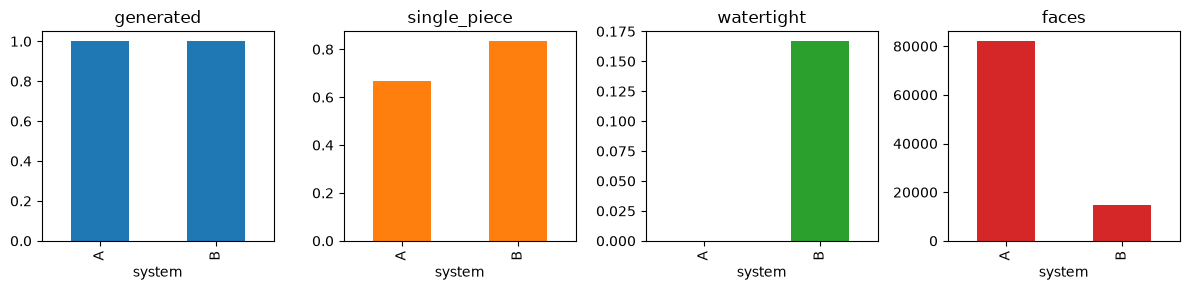

In [6]:
summary.plot(kind="bar", subplots=True, layout=(1, 4), figsize=(12, 3), legend=False)
plt.tight_layout()
plt.savefig("results/p3/metrics.png")

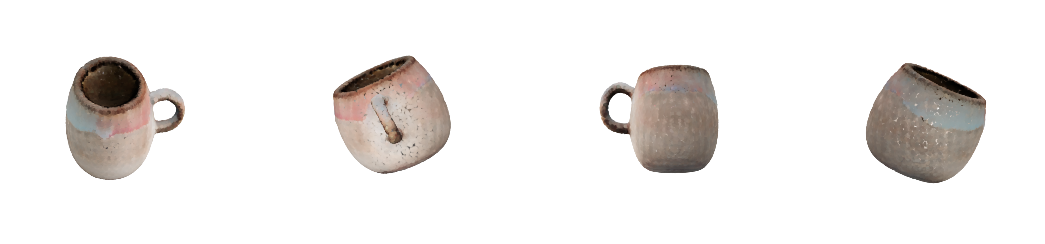

In [7]:
# Look at one object from both systems
Image.open("outputs/p3/A/o01_views.png")